# 03 – Exploratory Data Analysis (EDA)

## Project: HotelIQ – Hotel Booking Analytics & Cancellation Intelligence Platform

### Objective
The objective of this notebook is to perform exploratory data analysis on the cleaned hotel booking dataset to identify important patterns, trends and relationships.

### Analysis Areas
1. Hotel booking distribution.
2. Booking cancellation analysis.
3. Monthly and yearly booking trends.
4. Market segment and distribution channel analysis.
5. Lead time and cancellation behaviour.
6. Customer and stay analysis.
7. Pricing and ADR analysis.
8. Special requests and cancellation behaviour.

### Dataset
- Source: Cleaned Hotel Booking Demand Dataset.
- Records: 87,395.
- Features: 31.

### Expected Outcome
Identify meaningful business insights that can help hotels understand booking patterns, cancellation behaviour and customer preferences.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('../data/hotel_bookings_cleaned.csv')


In [3]:
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (87395, 31)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,-1.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,-1.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,-1.0,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87395 entries, 0 to 87394
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87395 non-null  str           
 1   is_canceled                     87395 non-null  int64         
 2   lead_time                       87395 non-null  int64         
 3   arrival_date_year               87395 non-null  int64         
 4   arrival_date_month              87395 non-null  str           
 5   arrival_date_week_number        87395 non-null  int64         
 6   arrival_date_day_of_month       87395 non-null  int64         
 7   stays_in_weekend_nights         87395 non-null  int64         
 8   stays_in_week_nights            87395 non-null  int64         
 9   adults                          87395 non-null  int64         
 10  children                        87395 non-null  float64       
 11  babies       

In [5]:
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
is_canceled,87395.0,0.274901,0.0,0.0,0.0,1.0,1.0,0.446467
lead_time,87395.0,79.890051,0.0,11.0,49.0,125.0,737.0,86.051937
arrival_date_year,87395.0,2016.210287,2015.0,2016.0,2016.0,2017.0,2017.0,0.686101
arrival_date_week_number,87395.0,26.838526,1.0,16.0,27.0,37.0,53.0,13.674531
arrival_date_day_of_month,87395.0,15.815665,1.0,8.0,16.0,23.0,31.0,8.835121
stays_in_weekend_nights,87395.0,1.005229,0.0,0.0,1.0,2.0,19.0,1.031877
stays_in_week_nights,87395.0,2.625356,0.0,1.0,2.0,4.0,50.0,2.053564
adults,87395.0,1.875794,0.0,2.0,2.0,2.0,55.0,0.626504
children,87395.0,0.138635,0.0,0.0,0.0,0.0,10.0,0.455874
babies,87395.0,0.010824,0.0,0.0,0.0,0.0,10.0,0.113597


#### Hotel Booking Distribution

hotel
City Hotel      53428
Resort Hotel    33967
Name: count, dtype: int64

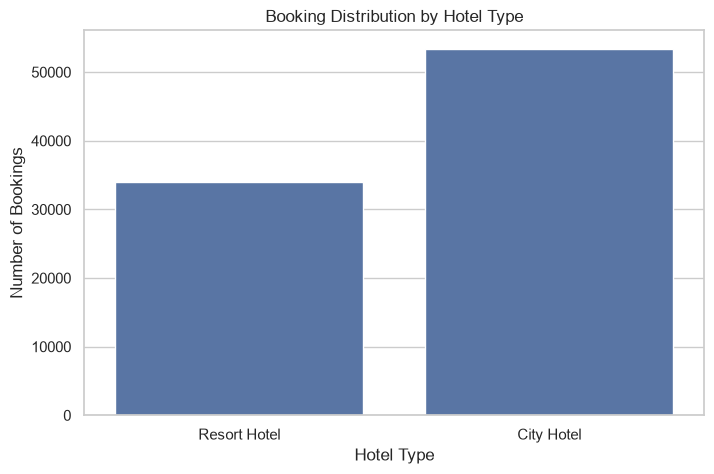

In [6]:
# Bookings by Hotel Type
hotel_counts = df['hotel'].value_counts()

display(hotel_counts)

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='hotel')

plt.title("Booking Distribution by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

plt.show()

In [7]:
#Booking Percentage by Hotel
#Which Hotel Type receives more booking?
hotel_percentage = (df['hotel'].value_counts(normalize=True)*100)

display(hotel_percentage)

hotel
City Hotel      61.133932
Resort Hotel    38.866068
Name: proportion, dtype: float64

##### Key Findings

- City Hotels received 53,428 bookings, accounting for approximately 61.13% of total bookings.
- Resort Hotels received 33,967 bookings, accounting for approximately 38.87%.
- City Hotels received a considerably higher number of bookings than Resort Hotels.

**Business Insight:** City Hotels contribute a larger share of total booking volume in the dataset.

#### Booking Cancellation Analysis

is_canceled
0    63370
1    24025
Name: count, dtype: int64

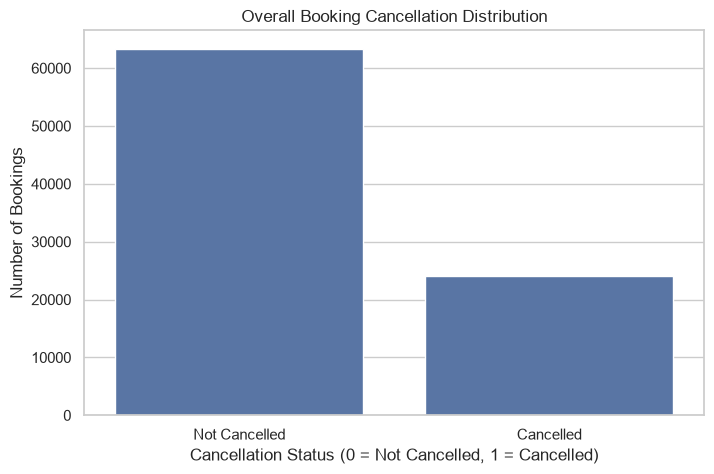

In [8]:
cancellation_counts = df['is_canceled'].value_counts()

display(cancellation_counts)

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='is_canceled')

plt.title('Overall Booking Cancellation Distribution')
plt.xlabel('Cancellation Status (0 = Not Cancelled, 1 = Cancelled)')
plt.ylabel('Number of Bookings')

plt.xticks([0, 1], ['Not Cancelled', 'Cancelled'])

plt.show()

In [9]:
#Cancellation percentage
cancellation_percentage = (df['is_canceled'].value_counts(normalize=True) * 100)

display(cancellation_percentage)

is_canceled
0    72.509869
1    27.490131
Name: proportion, dtype: float64

hotel
City Hotel      30.038557
Resort Hotel    23.481615
Name: is_canceled, dtype: float64

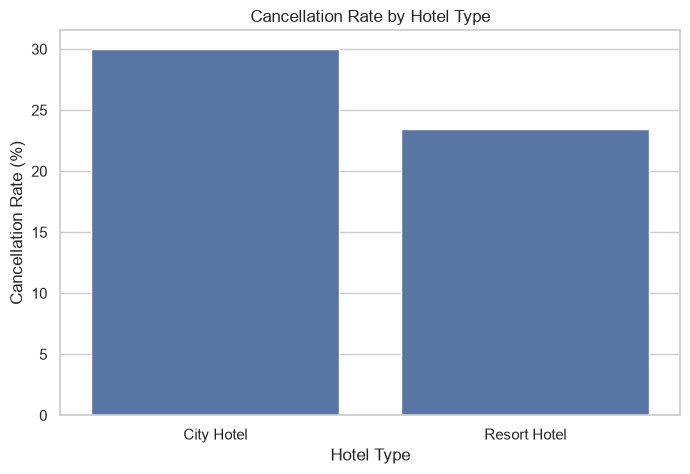

In [10]:
#Cancellation rate by hotel type
#Which hotel experience a higher cancellation rate?
hotel_cancellation = (df.groupby('hotel')['is_canceled'].mean() * 100)

display(hotel_cancellation)

plt.figure(figsize=(8, 5))

sns.barplot(x=hotel_cancellation.index, y=hotel_cancellation.values)

plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')

plt.show()

##### Key Findings

- Out of 87,395 bookings, 24,025 were canceled and 63,370 were not canceled.
- The overall cancellation rate is approximately 27.49%.
- City Hotels have a higher cancellation rate (30.04%) compared to Resort Hotels (23.48%).

**Business Insight:** City Hotels experience a higher cancellation rate, making cancellation management an important area for further investigation.

#### Monthly and Yearly Booking Trends

arrival_date_month
January       4693
February      6098
March         7512
April         7908
May           8355
June          7765
July         10057
August       11257
September     6690
October       6934
November      4995
December      5131
Name: count, dtype: int64

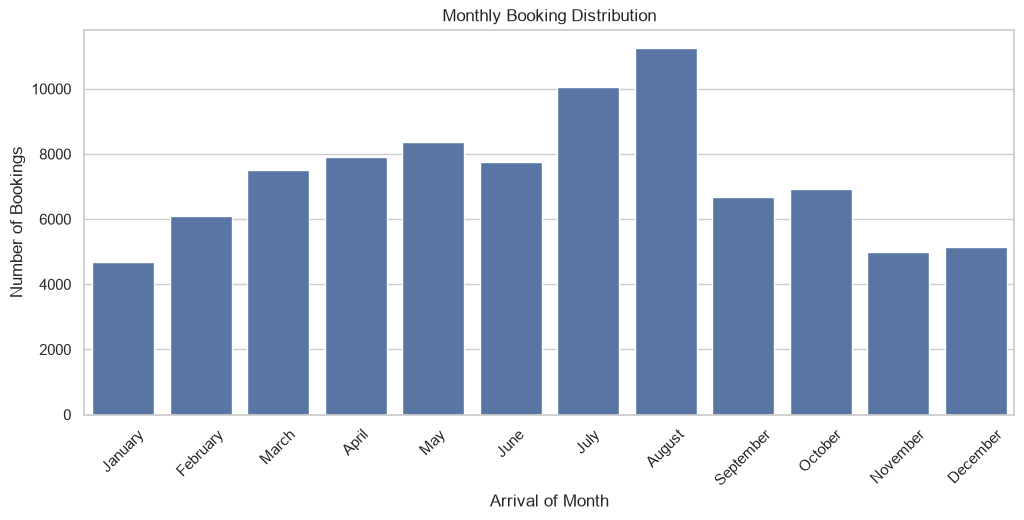

In [11]:

#Bookings by Arrival Month

month_order = [    'January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_bookings = df['arrival_date_month'].value_counts().reindex(month_order)

display(monthly_bookings)

plt.figure(figsize = (12, 5))

sns.barplot(x=monthly_bookings.index, y=monthly_bookings.values)

plt.title("Monthly Booking Distribution")
plt.xlabel("Arrival of Month")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)

plt.show()

arrival_date_month
January      22.118048
February     23.204329
March        24.361022
April        30.462822
May          29.228007
June         30.315518
July         31.798747
August       32.184419
September    24.544096
October      23.680415
November     21.101101
December     26.856363
Name: is_canceled, dtype: float64

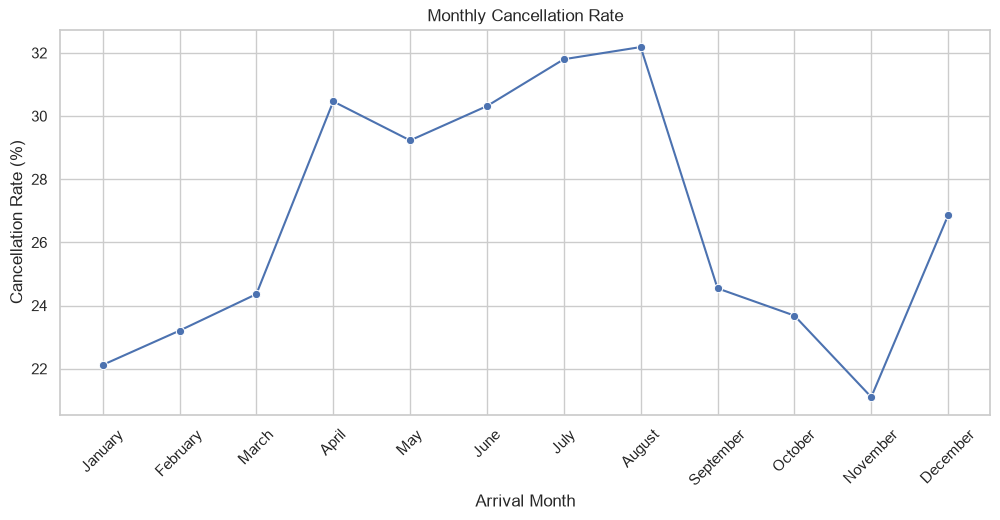

In [12]:
#Monthly Cancellatio  Rate

monthly_cancellation = (df.groupby('arrival_date_month')['is_canceled'].mean() * 100).reindex(month_order)

display(monthly_cancellation)

plt.figure(figsize=(12, 5))

sns.lineplot(x=monthly_cancellation.index, y=monthly_cancellation.values, marker='o')

plt.title('Monthly Cancellation Rate')
plt.xlabel('Arrival Month')
plt.ylabel('Cancellation Rate (%)')

plt.xticks(rotation=45)

plt.show()

arrival_date_year
2015    13313
2016    42391
2017    31691
Name: count, dtype: int64

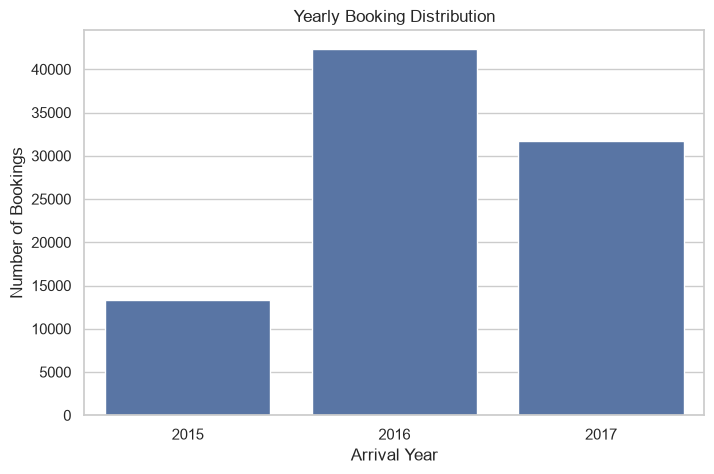

In [13]:
# Yearly Booking Distribution

yearly_bookings = df['arrival_date_year'].value_counts().sort_index()

display(yearly_bookings)

plt.figure(figsize=(8, 5))

sns.barplot(x=yearly_bookings.index, y=yearly_bookings.values)

plt.title('Yearly Booking Distribution')
plt.xlabel('Arrival Year')
plt.ylabel('Number of Bookings')

plt.show()

##### Key Findings

- August recorded the highest number of bookings (11,257), followed by July (10,057).
- January recorded the lowest number of bookings (4,693).
- August also recorded the highest monthly cancellation rate at approximately 32.18%.
- November had the lowest monthly cancellation rate at approximately 21.10%.
- 2016 recorded the highest booking count (42,391), followed by 2017 (31,691) and 2015 (13,313).

**Business Insight:** Booking activity and cancellation rates vary across months, indicating seasonal patterns in hotel reservations. Yearly booking counts should be interpreted with consideration of the dataset's coverage for each year.

#### Market Segment Analysis

market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4941
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64

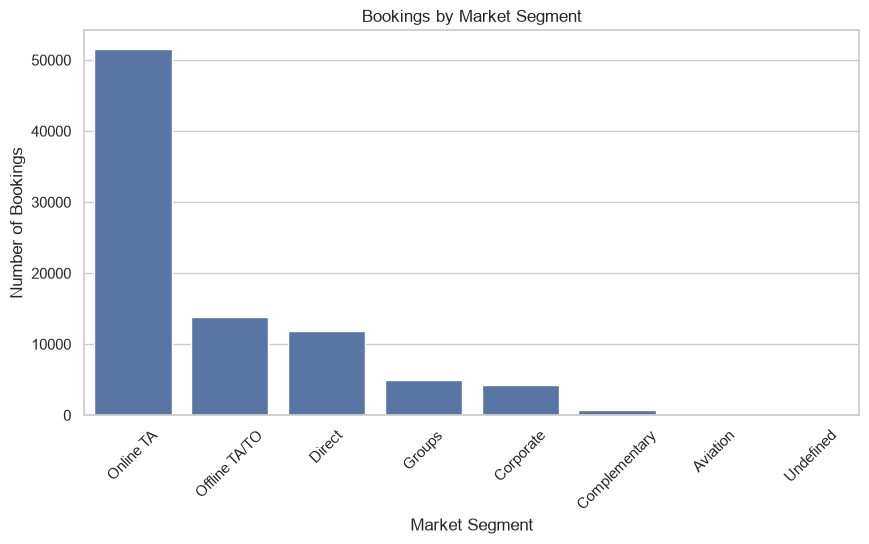

In [14]:
market_bookings = df['market_segment'].value_counts()

display(market_bookings)

plt.figure(figsize=(10, 5))

sns.barplot(x=market_bookings.index, y=market_bookings.values)

plt.title('Bookings by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.show()

market_segment
Undefined        100.000000
Online TA         35.346197
Groups            27.018822
Aviation          19.823789
Offline TA/TO     14.853481
Direct            14.715351
Complementary     12.535613
Corporate         12.108262
Name: is_canceled, dtype: float64

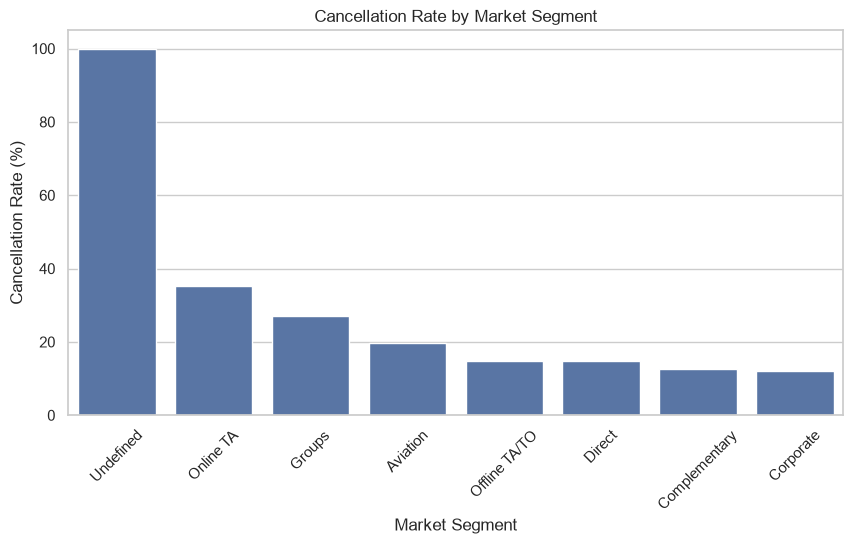

In [15]:
# Cancellation Rate by Market Segment
# WHich market segments contribute the most bookings and 
# which have the highest cancellation rates?

market_cancellation = (df.groupby('market_segment')['is_canceled']
    .mean() * 100).sort_values(ascending=False)

display(market_cancellation)

plt.figure(figsize=(10, 5))

sns.barplot(x=market_cancellation.index, y=market_cancellation.values)

plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Cancellation Rate (%)')

plt.xticks(rotation=45)

plt.show()

##### Key Findings

- Online Travel Agents (Online TA) generated the highest number of bookings (51,618).
- Offline TA/TO was the second-largest segment with 13,889 bookings.
- Online TA recorded a cancellation rate of approximately 35.35%.
- Groups had a cancellation rate of approximately 27.02%.
- Corporate bookings had the lowest cancellation rate among the main segments, at approximately 12.11%.
- The Undefined segment shows a 100% cancellation rate, but it contains only two bookings.

**Business Insight:** Online TA is the dominant booking channel but also has a relatively high cancellation rate. This segment deserves further investigation.

#### Lead Time Analysis

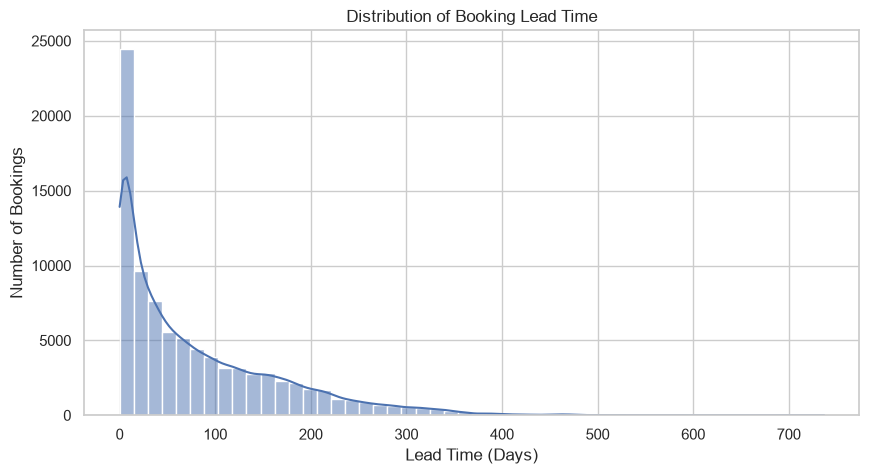

In [16]:
# Lead represents the days between number of days between bookinga dn arrival.
#Lead Time Distribution

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='lead_time', bins=50, kde=True)

plt.title('Distribution of Booking Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Bookings')

plt.show()

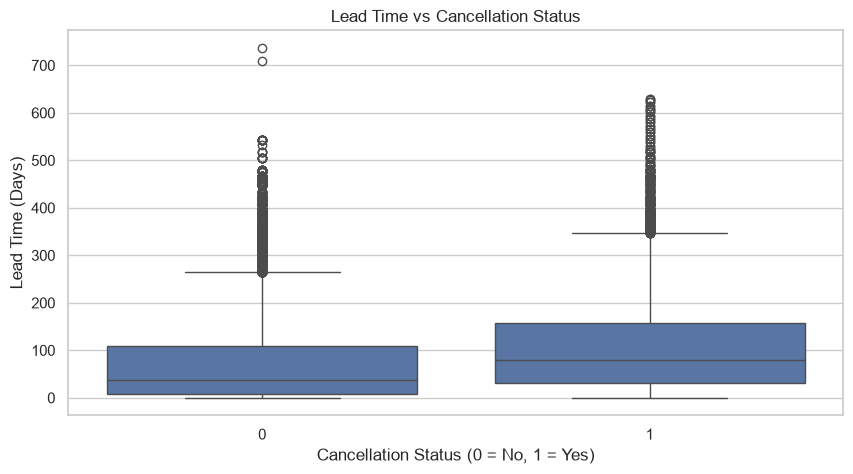

In [17]:
#Lead Time VS Cancellation

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='is_canceled', y='lead_time')

plt.title('Lead Time vs Cancellation Status')
plt.xlabel('Cancellation Status (0 = No, 1 = Yes)')
plt.ylabel('Lead Time (Days)')

plt.show()

lead_time_group
0-30 Days       16.418427
31-90 Days      32.008442
91-180 Days     34.983281
181-365 Days    39.682114
365+ Days       40.884956
Name: is_canceled, dtype: float64

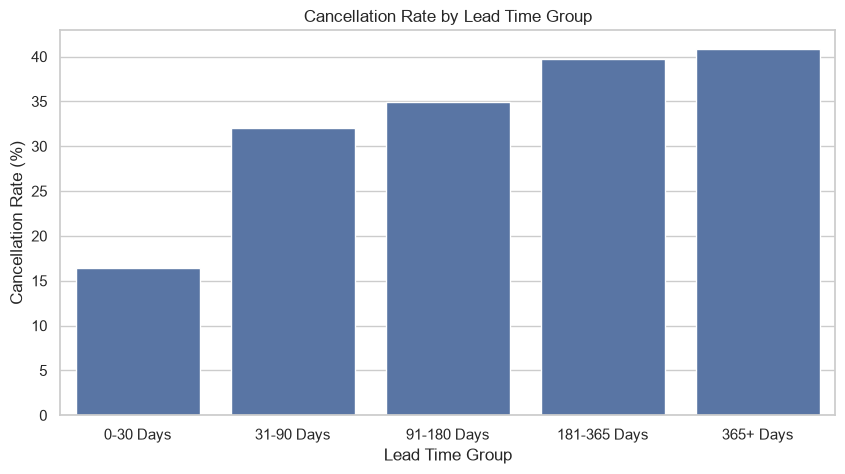

In [18]:
# Cancellation Rate by Lead Time Groups

df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=[-1, 30, 90, 180, 365, float('inf')],
    labels=['0-30 Days', '31-90 Days', '91-180 Days', '181-365 Days', '365+ Days'])

lead_time_cancellation = (df.groupby('lead_time_group', observed=False)['is_canceled'].mean() * 100)

display(lead_time_cancellation)

plt.figure(figsize=(10, 5))

sns.barplot(x=lead_time_cancellation.index, y=lead_time_cancellation.values)

plt.title('Cancellation Rate by Lead Time Group')
plt.xlabel('Lead Time Group')
plt.ylabel('Cancellation Rate (%)')

plt.show()

##### Key Findings

- The average booking lead time is approximately 79.89 days.
- Bookings made within 0–30 days have the lowest cancellation rate (16.42%).
- Cancellation rates increase as lead time increases.
- Bookings made 365+ days in advance have the highest cancellation rate (40.88%).
- The 181–365 days group also has a high cancellation rate of approximately 39.68%.

**Business Insight:** Bookings made further in advance are associated with higher cancellation rates. Hotels may benefit from monitoring long-lead-time reservations more closely.

#### Customer and Stay Analysis

customer_type
Transient          71986
Transient-Party    11726
Contract            3139
Group                544
Name: count, dtype: int64

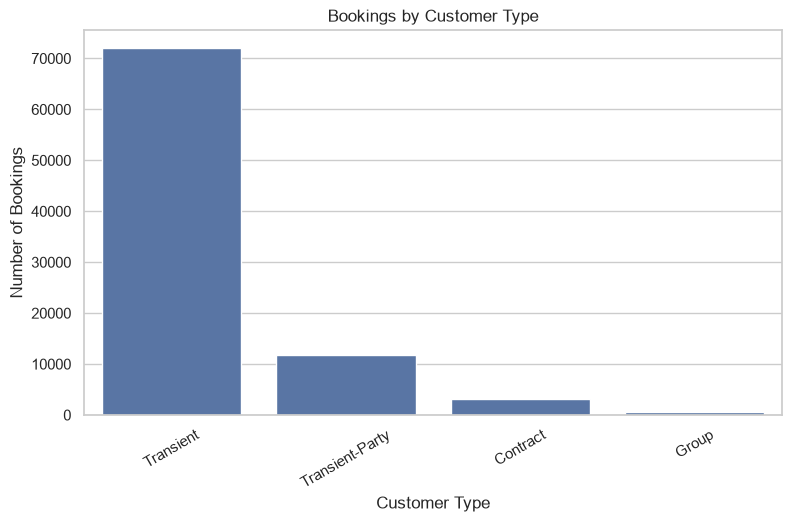

In [19]:
# Customer Type Distribution

customer_counts = df['customer_type'].value_counts()

display(customer_counts)

plt.figure(figsize=(9, 5))

sns.barplot(x=customer_counts.index, y=customer_counts.values)

plt.title('Bookings by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=30)

plt.show()

customer_type
Transient          30.105854
Contract           16.310927
Transient-Party    15.239638
Group               9.926471
Name: is_canceled, dtype: float64

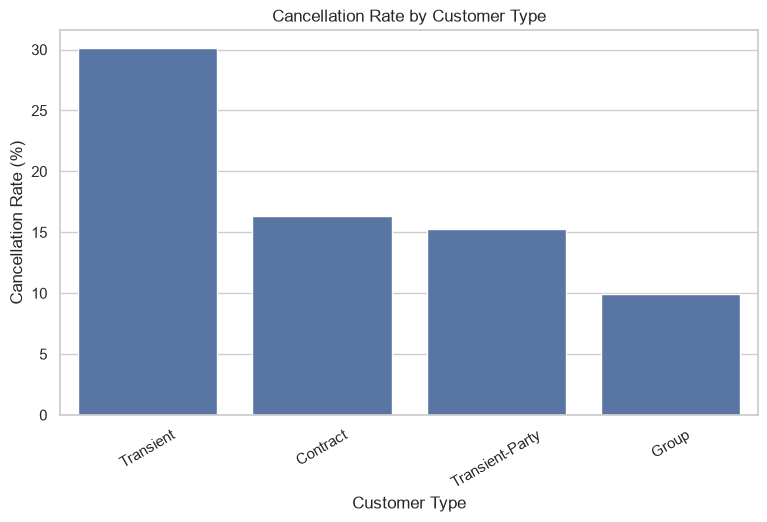

In [20]:
# Cancellation Rate by Customer Type

customer_cancellation = (df.groupby('customer_type')['is_canceled']
                         .mean() * 100).sort_values(ascending=False)

display(customer_cancellation)

plt.figure(figsize=(9, 5))

sns.barplot(x=customer_cancellation.index, y=customer_cancellation.values)

plt.title('Cancellation Rate by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Cancellation Rate (%)')

plt.xticks(rotation=30)

plt.show()

In [21]:
# Total Stay Duration

df['total_stay_nights'] = (df['stays_in_weekend_nights'] + df['stays_in_week_nights'])

display(df['total_stay_nights'].describe())

count    87395.000000
mean         3.630585
std          2.763381
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         69.000000
Name: total_stay_nights, dtype: float64

total_stay_nights
0      4.454685
1     18.395019
2     26.706891
3     29.979259
4     30.497238
5     30.376743
6     34.484867
7     30.676232
8     37.394564
9     35.128205
10    31.255814
11    29.189189
12    38.693467
13    36.567164
14    25.870070
15    48.611111
16    48.484848
17    25.000000
18    75.000000
19    72.727273
Name: is_canceled, dtype: float64

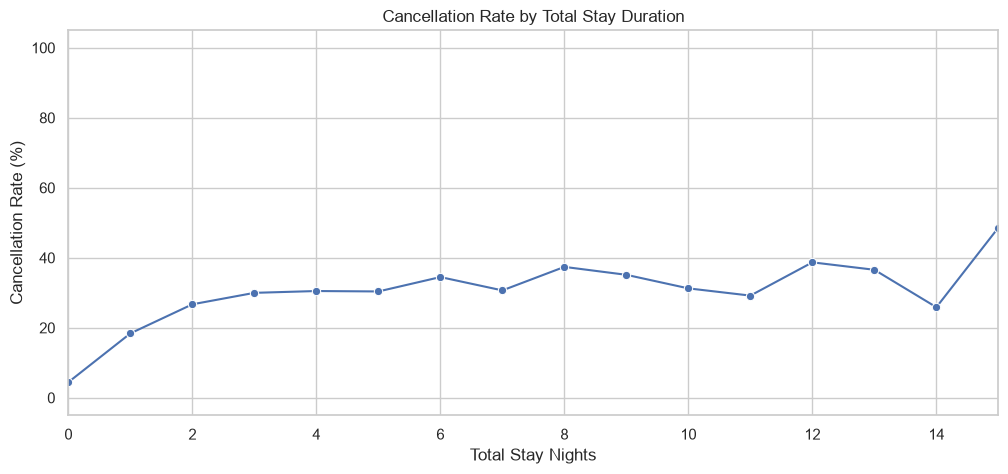

In [22]:
# Stay Duration VS Cancellation

stay_cancellation = (df.groupby('total_stay_nights')['is_canceled'].mean() * 100)

display(stay_cancellation.head(20))

plt.figure(figsize=(12, 5))

sns.lineplot(x=stay_cancellation.index, y=stay_cancellation.values, marker='o')

plt.title('Cancellation Rate by Total Stay Duration')
plt.xlabel('Total Stay Nights')
plt.ylabel('Cancellation Rate (%)')

plt.xlim(0, 15)

plt.show()

##### Key Findings

- Transient customers represent the largest customer segment, with 71,986 bookings.
- Transient customers also have the highest cancellation rate (30.11%).
- Group customers have the lowest cancellation rate (9.93%).
- The average stay duration is approximately 3.63 nights.
- The cancellation rate generally increases across several stay-duration groups, although the pattern is not consistently increasing.

**Business Insight:** Transient customers contribute the majority of bookings and have a relatively high cancellation rate. Customer type and stay duration may provide useful information for understanding cancellation behaviour.

#### Pricing and ADR Analysis

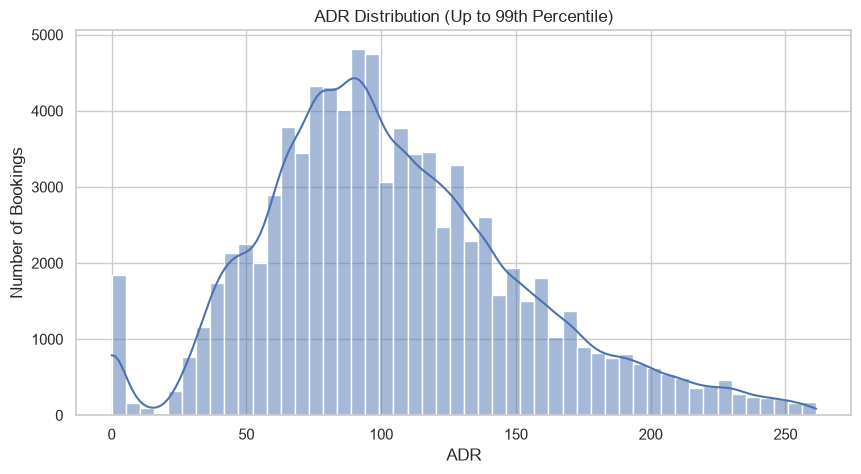

In [ ]:
# ADR stands for Average Daily Rate
# ADR Distribution 

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['adr'] <= df['adr'].quantile(0.99)], x='adr', bins=50, kde=True)

plt.title('ADR Distribution (Up to 99th Percentile)')
plt.xlabel('ADR')
plt.ylabel('Number of Bookings')

plt.show()

hotel
City Hotel      110.985944
Resort Hotel     99.028449
Name: adr, dtype: float64

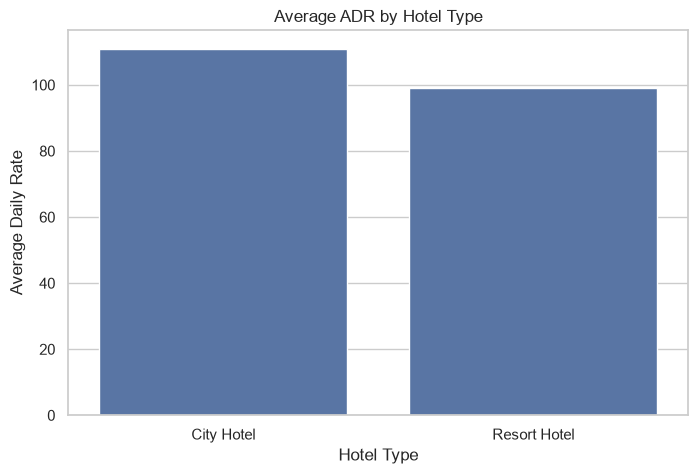

In [26]:
# ADR by Hotel Type

adr_by_hotel = df.groupby('hotel')['adr'].mean()

display(adr_by_hotel)

plt.figure(figsize=(8, 5))

sns.barplot(x=adr_by_hotel.index, y=adr_by_hotel.values)

plt.title('Average ADR by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate')

plt.show()

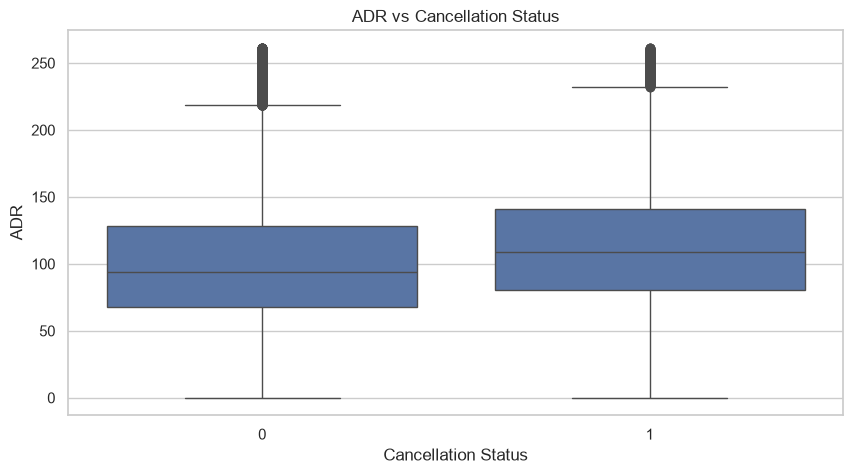

In [27]:
# ADR VS Cancellation

plt.figure(figsize=(10, 5))

sns.boxplot(data=df[df['adr'] <= df['adr'].quantile(0.99)], x='is_canceled', y='adr')

plt.title('ADR vs Cancellation Status')
plt.xlabel('Cancellation Status')
plt.ylabel('ADR')

plt.show()

##### Key Findings

- City Hotels have an average ADR of approximately 110.99.
- Resort Hotels have an average ADR of approximately 99.03.
- City Hotels therefore have a higher average daily rate than Resort Hotels.
- The ADR distribution is visualized up to the 99th percentile to reduce the visual influence of extreme values.
- ADR also varies between canceled and non-canceled bookings, which can be explored further through statistical analysis.

**Business Insight:** Pricing patterns differ between hotel types. ADR can help understand room pricing behaviour, but it should not be treated as actual revenue.

#### Special Requests Analysis

total_of_special_requests
0    43893
1    29017
2    11812
3     2317
4      320
5       36
Name: count, dtype: int64

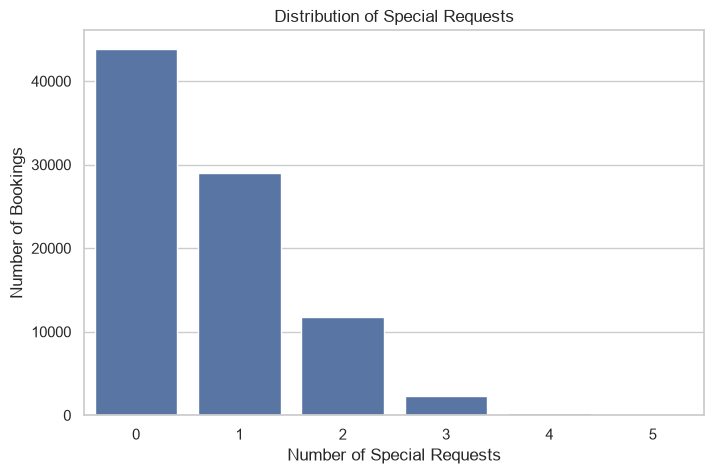

In [28]:
# Special Request Distribution

special_requests = df['total_of_special_requests'].value_counts().sort_index()

display(special_requests)

plt.figure(figsize=(8, 5))

sns.barplot(x=special_requests.index, y=special_requests.values)

plt.title('Distribution of Special Requests')
plt.xlabel('Number of Special Requests')
plt.ylabel('Number of Bookings')

plt.show()

total_of_special_requests
0    33.203472
1    22.411000
2    21.291907
3    17.134225
4    10.625000
5     5.555556
Name: is_canceled, dtype: float64

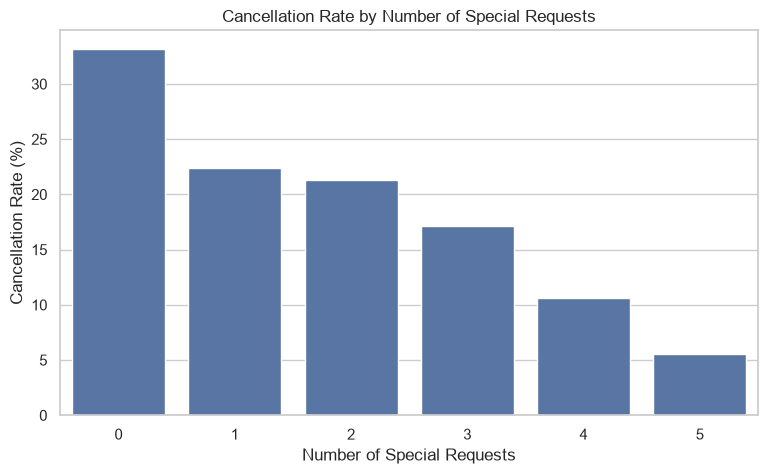

In [29]:
# Special Requests VS Cancellation

special_request_cancellation = (df.groupby('total_of_special_requests')['is_canceled'].mean() * 100)

display(special_request_cancellation)

plt.figure(figsize=(9, 5))

sns.barplot(x=special_request_cancellation.index, y=special_request_cancellation.values)

plt.title('Cancellation Rate by Number of Special Requests')
plt.xlabel('Number of Special Requests')
plt.ylabel('Cancellation Rate (%)')

plt.show()

##### Key Findings

- 43,893 bookings had no special requests.
- 29,017 bookings had one special request.
- Bookings with zero special requests had a cancellation rate of approximately 33.20%.
- Cancellation rates generally decrease as the number of special requests increases.
- Bookings with five special requests had a cancellation rate of approximately 5.56%, although this group contains only 36 bookings.

**Business Insight:** Bookings with more special requests are associated with lower cancellation rates. Special requests may provide useful information about customer engagement and booking commitment.

#### Final EDA Summary

In [30]:
print("=" * 50)
print("HOTELIQ - EDA SUMMARY")
print("=" * 50)

print("\nTotal Bookings:", len(df))

print("\nHotel Distribution:")
print(df['hotel'].value_counts())

print("\nCancellation Distribution:")
print(df['is_canceled'].value_counts(normalize=True) * 100)

print("\nCancellation Rate by Hotel:")
print(df.groupby('hotel')['is_canceled'].mean() * 100)

print("\nTop Market Segments:")
print(df['market_segment'].value_counts().head())

print("\nCancellation Rate by Customer Type:")
print(df.groupby('customer_type')['is_canceled'].mean() * 100)

print("\nAverage ADR by Hotel:")
print(df.groupby('hotel')['adr'].mean())

print("\nAverage Lead Time:", df['lead_time'].mean())

print("\nAverage Stay Duration:", df['total_stay_nights'].mean())

HOTELIQ - EDA SUMMARY

Total Bookings: 87395

Hotel Distribution:
hotel
City Hotel      53428
Resort Hotel    33967
Name: count, dtype: int64

Cancellation Distribution:
is_canceled
0    72.509869
1    27.490131
Name: proportion, dtype: float64

Cancellation Rate by Hotel:
hotel
City Hotel      30.038557
Resort Hotel    23.481615
Name: is_canceled, dtype: float64

Top Market Segments:
market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4941
Corporate         4212
Name: count, dtype: int64

Cancellation Rate by Customer Type:
customer_type
Contract           16.310927
Group               9.926471
Transient          30.105854
Transient-Party    15.239638
Name: is_canceled, dtype: float64

Average ADR by Hotel:
hotel
City Hotel      110.985944
Resort Hotel     99.028449
Name: adr, dtype: float64

Average Lead Time: 79.89005091824475

Average Stay Duration: 3.63058527375708


## Final EDA Summary & Conclusion

### Overall Findings

1. **Hotel Distribution:** City Hotels account for approximately 61.13% of bookings, making them the dominant hotel type.
2. **Cancellation Behaviour:** The overall cancellation rate is 27.49%, with City Hotels experiencing more cancellations than Resort Hotels.
3. **Seasonal Trends:** August records the highest booking volume, while January records the lowest.
4. **Market Segments:** Online TA is the largest market segment and has a relatively high cancellation rate.
5. **Lead Time:** Longer booking lead times are associated with higher cancellation rates.
6. **Customer Behaviour:** Transient customers represent the largest customer segment and have the highest cancellation rate.
7. **Pricing:** City Hotels have a higher average ADR than Resort Hotels.
8. **Special Requests:** Bookings with more special requests generally show lower cancellation rates.

### Conclusion

The exploratory data analysis identified several patterns in hotel booking behaviour, including differences in cancellation rates, seasonal booking demand, market segment performance, customer types, lead time, pricing, and special requests.

These findings highlight potential factors associated with booking cancellations and provide a foundation for further statistical investigation.

The next stage of HotelIQ will use statistical hypothesis testing to determine whether selected relationships observed during EDA are statistically significant.